# Individual Task 2 — Part 2 Deliberation: Supporting Analysis Notebook


## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, make_scorer)

from fairlearn.metrics import MetricFrame, demographic_parity_difference, equalized_odds_difference
from fairlearn.metrics import selection_rate, true_positive_rate, false_positive_rate

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
np.random.seed(RANDOM_STATE)


## 1. Load and preprocess datasets

Same cleaning as Task 1 Part 1:
- **Telco**: coerce `TotalCharges` to numeric (drop the blanks), drop `customerID`, map `Churn` to 0/1,
  one-hot encode remaining categorical columns.
- **Bank**: drop `customer_id`, one-hot encode `country` and `gender`.

In [2]:
telco = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')  # place this file next to the notebook

telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
telco = telco.dropna(subset=['TotalCharges'])
telco = telco.drop(columns=['customerID'])
telco['Churn'] = telco['Churn'].map({'Yes': 1, 'No': 0})

# keep the raw sensitive columns aside (pre-encoding) for the fairness audit later
telco_gender = telco['gender'].copy()
telco_senior = telco['SeniorCitizen'].copy()  # already 0/1 in the raw data

cat_cols = telco.select_dtypes(include='object').columns.tolist()
telco_encoded = pd.get_dummies(telco, columns=cat_cols, drop_first=True)

print(f"Telco shape after cleaning: {telco.shape}")
print(f"Telco shape after encoding: {telco_encoded.shape}")
print(telco['Churn'].value_counts(normalize=True).round(3))


Telco shape after cleaning: (7032, 20)
Telco shape after encoding: (7032, 31)
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


/tmp/ipykernel_678/2825978972.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = telco.select_dtypes(include='object').columns.tolist()


In [3]:
bank = pd.read_csv('Bank Customer Churn Prediction.csv')

bank_gender = bank['gender'].copy()
bank_country = bank['country'].copy()
bank_age_band = pd.cut(bank['age'], bins=[0, 35, 50, 200], labels=['18-35', '36-50', '51+'])

bank = bank.drop(columns=['customer_id'])
bank_encoded = pd.get_dummies(bank, columns=['country', 'gender'], drop_first=True)

print(f"Bank shape: {bank.shape}")
print(f"Bank encoded shape: {bank_encoded.shape}")
print(bank['churn'].value_counts(normalize=True).round(3))


Bank shape: (10000, 11)
Bank encoded shape: (10000, 12)
churn
0    0.796
1    0.204
Name: proportion, dtype: float64


## 2. Baseline: reproduce the original single 80/20 split
Same `train_test_split` call, same hyperparameters, as Task 1 Part 1.

In [4]:
X_telco = telco_encoded.drop(columns=['Churn'])
y_telco = telco_encoded['Churn']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_telco, y_telco, test_size=0.2, random_state=RANDOM_STATE, stratify=y_telco)

scaler_t = StandardScaler()
X_train_t_scaled = scaler_t.fit_transform(X_train_t)
X_test_t_scaled = scaler_t.transform(X_test_t)

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_t_scaled, y_train_t)

y_pred_knn = knn.predict(X_test_t_scaled)
y_prob_knn = knn.predict_proba(X_test_t_scaled)[:, 1]

baseline_knn = {
    'accuracy': accuracy_score(y_test_t, y_pred_knn),
    'precision': precision_score(y_test_t, y_pred_knn),
    'recall': recall_score(y_test_t, y_pred_knn),
    'f1': f1_score(y_test_t, y_pred_knn),
    'roc_auc': roc_auc_score(y_test_t, y_prob_knn),
}
print('kNN / Telco — single 80/20 split baseline')
for k, v in baseline_knn.items():
    print(f'  {k:>9}: {v:.3f}')


kNN / Telco — single 80/20 split baseline
   accuracy: 0.771
  precision: 0.573
     recall: 0.543
         f1: 0.558
    roc_auc: 0.805


In [5]:
X_bank = bank_encoded.drop(columns=['churn'])
y_bank = bank_encoded['churn']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bank, y_bank, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bank)

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE)
rf.fit(X_train_b, y_train_b)

y_pred_rf = rf.predict(X_test_b)
y_prob_rf = rf.predict_proba(X_test_b)[:, 1]

baseline_rf = {
    'accuracy': accuracy_score(y_test_b, y_pred_rf),
    'precision': precision_score(y_test_b, y_pred_rf),
    'recall': recall_score(y_test_b, y_pred_rf),
    'f1': f1_score(y_test_b, y_pred_rf),
    'roc_auc': roc_auc_score(y_test_b, y_prob_rf),
}
print('Random Forest / Bank — single 80/20 split baseline')
for k, v in baseline_rf.items():
    print(f'  {k:>9}: {v:.3f}')


Random Forest / Bank — single 80/20 split baseline
   accuracy: 0.868
  precision: 0.820
     recall: 0.447
         f1: 0.579
    roc_auc: 0.864


## 3. Section 2.1 — Stratified 5-fold cross-validation

For kNN, the `StandardScaler` is folded **inside** a `Pipeline`, so scaling is fit only on each
training fold and never sees the validation fold (avoids scaling leakage). Random Forest needs no
scaling, so it is cross-validated directly.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
}

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=15)),
])

cv_results_knn = cross_validate(knn_pipeline, X_telco, y_telco, cv=cv, scoring=scoring)

print('kNN / Telco — 5-fold stratified CV (mean ± SD)')
for metric in scoring:
    vals = cv_results_knn[f'test_{metric}']
    print(f'  {metric:>9}: {vals.mean():.3f} ± {vals.std():.3f}')


kNN / Telco — 5-fold stratified CV (mean ± SD)
   accuracy: 0.781 ± 0.005
  precision: 0.596 ± 0.016
     recall: 0.556 ± 0.021
         f1: 0.575 ± 0.008
    roc_auc: 0.813 ± 0.004


In [7]:
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE)

cv_results_rf = cross_validate(rf_model, X_bank, y_bank, cv=cv, scoring=scoring)

print('Random Forest / Bank — 5-fold stratified CV (mean ± SD)')
for metric in scoring:
    vals = cv_results_rf[f'test_{metric}']
    print(f'  {metric:>9}: {vals.mean():.3f} ± {vals.std():.3f}')


Random Forest / Bank — 5-fold stratified CV (mean ± SD)
   accuracy: 0.864 ± 0.005
  precision: 0.808 ± 0.024
     recall: 0.435 ± 0.026
         f1: 0.565 ± 0.023
    roc_auc: 0.863 ± 0.006


In [8]:
summary_rows = []
for name, baseline, cvres in [
    ('kNN / Telco', baseline_knn, cv_results_knn),
    ('RF / Bank', baseline_rf, cv_results_rf),
]:
    for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
        vals = cvres[f'test_{metric}']
        summary_rows.append({
            'Model / Dataset': name,
            'Metric': metric,
            'Original (single split)': round(baseline[metric], 3),
            '5-fold CV mean': round(vals.mean(), 3),
            '5-fold CV SD': round(vals.std(), 3),
        })

summary_table = pd.DataFrame(summary_rows)
summary_table


,Model / Dataset,Metric,Original (single split),5-fold CV mean,5-fold CV SD
0,kNN / Telco,accuracy,0.771,0.781,0.005
1,kNN / Telco,precision,0.573,0.596,0.016
2,kNN / Telco,recall,0.543,0.556,0.021
3,kNN / Telco,f1,0.558,0.575,0.008
4,kNN / Telco,roc_auc,0.805,0.813,0.004
5,RF / Bank,accuracy,0.868,0.864,0.005
6,RF / Bank,precision,0.820,0.808,0.024
7,RF / Bank,recall,0.447,0.435,0.026
8,RF / Bank,f1,0.579,0.565,0.023
9,RF / Bank,roc_auc,0.864,0.863,0.006


/tmp/ipykernel_678/1961226332.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=['Acc', 'Prec', 'Rec', 'F1', 'AUC'])
/tmp/ipykernel_678/1961226332.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=['Acc', 'Prec', 'Rec', 'F1', 'AUC'])


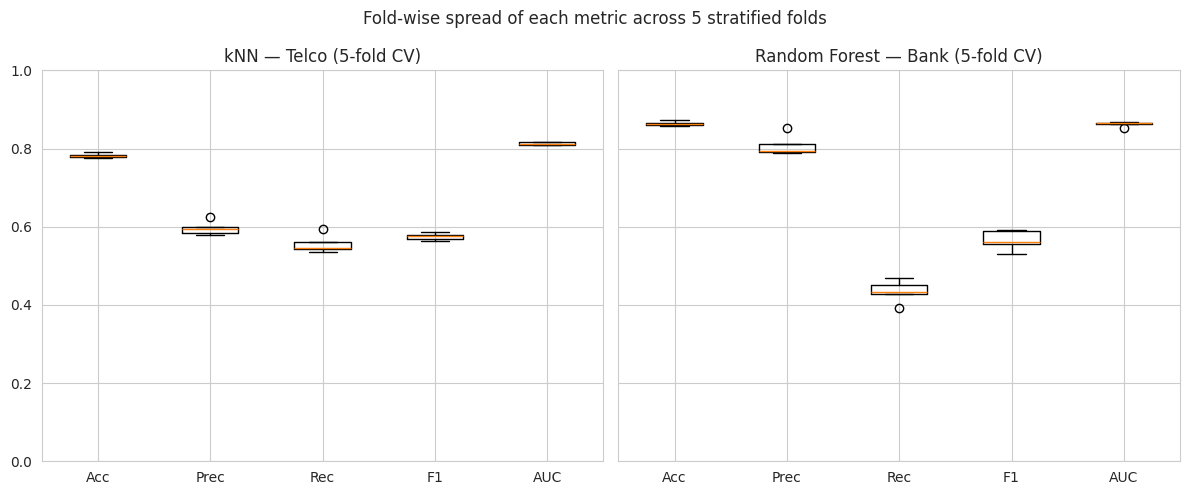

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, name, cvres in [
    (axes[0], 'kNN — Telco (5-fold CV)', cv_results_knn),
    (axes[1], 'Random Forest — Bank (5-fold CV)', cv_results_rf),
]:
    data = [cvres[f'test_{m}'] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']]
    ax.boxplot(data, labels=['Acc', 'Prec', 'Rec', 'F1', 'AUC'])
    ax.set_title(name)
    ax.set_ylim(0, 1)

fig.suptitle('Fold-wise spread of each metric across 5 stratified folds')
plt.tight_layout()
plt.savefig('fig1_cv_spread.png', dpi=150)
plt.show()


## 4. Section 2.2 — Learning curves

F1-score vs. training-set size, using the same 5-fold stratified CV.

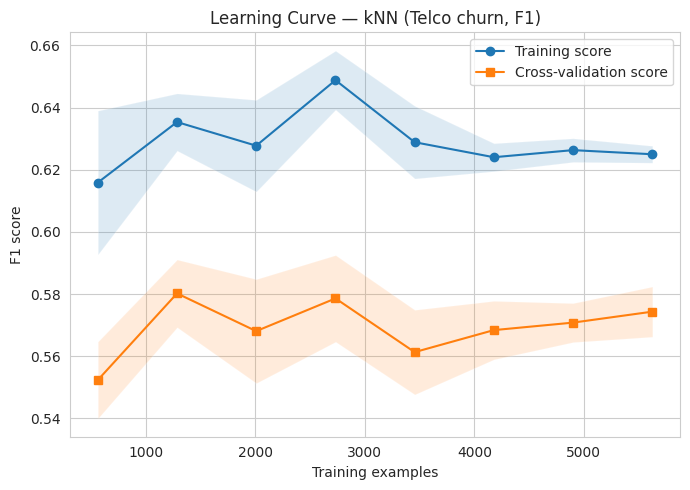

kNN train sizes: [ 562 1285 2008 2732 3455 4178 4901 5625]
kNN CV F1 by size: [0.552 0.58  0.568 0.579 0.561 0.568 0.571 0.574]


In [10]:
train_sizes = np.linspace(0.1, 1.0, 8)

train_sizes_abs_t, train_scores_t, val_scores_t = learning_curve(
    knn_pipeline, X_telco, y_telco, cv=cv, train_sizes=train_sizes,
    scoring=make_scorer(f1_score, zero_division=0), random_state=RANDOM_STATE, n_jobs=-1)

plt.figure(figsize=(7, 5))
plt.plot(train_sizes_abs_t, train_scores_t.mean(axis=1), 'o-', label='Training score')
plt.plot(train_sizes_abs_t, val_scores_t.mean(axis=1), 's-', label='Cross-validation score')
plt.fill_between(train_sizes_abs_t,
                  train_scores_t.mean(axis=1) - train_scores_t.std(axis=1),
                  train_scores_t.mean(axis=1) + train_scores_t.std(axis=1), alpha=0.15)
plt.fill_between(train_sizes_abs_t,
                  val_scores_t.mean(axis=1) - val_scores_t.std(axis=1),
                  val_scores_t.mean(axis=1) + val_scores_t.std(axis=1), alpha=0.15)
plt.xlabel('Training examples')
plt.ylabel('F1 score')
plt.title('Learning Curve — kNN (Telco churn, F1)')
plt.legend()
plt.tight_layout()
plt.savefig('fig2_learning_curve_knn.png', dpi=150)
plt.show()

print('kNN train sizes:', train_sizes_abs_t)
print('kNN CV F1 by size:', val_scores_t.mean(axis=1).round(3))


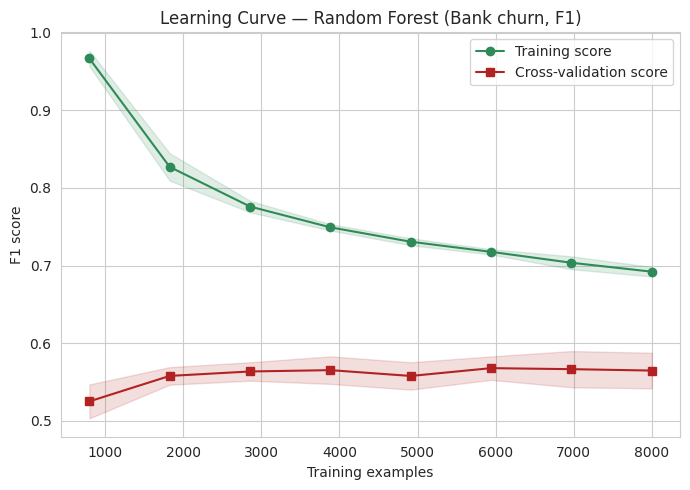

RF train sizes: [ 800 1828 2857 3885 4914 5942 6971 8000]
RF train F1 by size: [0.967 0.827 0.776 0.749 0.731 0.718 0.704 0.692]
RF CV F1 by size: [0.525 0.558 0.564 0.565 0.558 0.568 0.567 0.565]
Train/CV gap at smallest size: 0.441
Train/CV gap at largest size:  0.127


In [11]:
train_sizes_abs_b, train_scores_b, val_scores_b = learning_curve(
    rf_model, X_bank, y_bank, cv=cv, train_sizes=train_sizes,
    scoring=make_scorer(f1_score, zero_division=0), random_state=RANDOM_STATE, n_jobs=-1)

plt.figure(figsize=(7, 5))
plt.plot(train_sizes_abs_b, train_scores_b.mean(axis=1), 'o-', color='seagreen', label='Training score')
plt.plot(train_sizes_abs_b, val_scores_b.mean(axis=1), 's-', color='firebrick', label='Cross-validation score')
plt.fill_between(train_sizes_abs_b,
                  train_scores_b.mean(axis=1) - train_scores_b.std(axis=1),
                  train_scores_b.mean(axis=1) + train_scores_b.std(axis=1), alpha=0.15, color='seagreen')
plt.fill_between(train_sizes_abs_b,
                  val_scores_b.mean(axis=1) - val_scores_b.std(axis=1),
                  val_scores_b.mean(axis=1) + val_scores_b.std(axis=1), alpha=0.15, color='firebrick')
plt.xlabel('Training examples')
plt.ylabel('F1 score')
plt.title('Learning Curve — Random Forest (Bank churn, F1)')
plt.legend()
plt.tight_layout()
plt.savefig('fig3_learning_curve_rf.png', dpi=150)
plt.show()

print('RF train sizes:', train_sizes_abs_b)
print('RF train F1 by size:', train_scores_b.mean(axis=1).round(3))
print('RF CV F1 by size:', val_scores_b.mean(axis=1).round(3))
print(f'Train/CV gap at smallest size: {train_scores_b.mean(axis=1)[0] - val_scores_b.mean(axis=1)[0]:.3f}')
print(f'Train/CV gap at largest size:  {train_scores_b.mean(axis=1)[-1] - val_scores_b.mean(axis=1)[-1]:.3f}')


## 5. Section 2.3 — Bias audit with Fairlearn

Sensitive attributes:
- **Telco / kNN**: `gender`, `SeniorCitizen`
- **Bank / Random Forest**: `gender`, `country`, engineered `age_band` (18–35 / 36–50 / 51+)

All group metrics below are computed on the held-out test fold from the original 80/20 split
(same `X_test`/`y_test` used in Section 2), using each model's actual predictions on that fold.

In [12]:
# Recover the sensitive attributes for the SAME rows that ended up in the Telco test split
sens_telco_test = pd.DataFrame({
    'gender': telco_gender.loc[X_test_t.index],
    'SeniorCitizen': telco_senior.loc[X_test_t.index].map({0: 'Not senior', 1: 'Senior'}),
})

mf_gender_t = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score,
             'TPR': true_positive_rate, 'FPR': false_positive_rate},
    y_true=y_test_t, y_pred=y_pred_knn, sensitive_features=sens_telco_test['gender'])

mf_senior_t = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score,
             'TPR': true_positive_rate, 'FPR': false_positive_rate},
    y_true=y_test_t, y_pred=y_pred_knn, sensitive_features=sens_telco_test['SeniorCitizen'])

dpd_gender = demographic_parity_difference(y_test_t, y_pred_knn, sensitive_features=sens_telco_test['gender'])
eod_gender = equalized_odds_difference(y_test_t, y_pred_knn, sensitive_features=sens_telco_test['gender'])
dpd_senior = demographic_parity_difference(y_test_t, y_pred_knn, sensitive_features=sens_telco_test['SeniorCitizen'])
eod_senior = equalized_odds_difference(y_test_t, y_pred_knn, sensitive_features=sens_telco_test['SeniorCitizen'])

print('Telco / kNN — Gender')
print(mf_gender_t.by_group.round(3))
print(f'DPD = {dpd_gender:.3f}, EOD = {eod_gender:.3f}')
print()
print('Telco / kNN — Senior citizen status')
print(mf_senior_t.by_group.round(3))
print(f'DPD = {dpd_senior:.3f}, EOD = {eod_senior:.3f}')


Telco / kNN — Gender
        selection_rate  accuracy    TPR    FPR
gender                                        
Female           0.257     0.759  0.529  0.154
Male             0.247     0.782  0.556  0.139
DPD = 0.010, EOD = 0.027

Telco / kNN — Senior citizen status
               selection_rate  accuracy    TPR    FPR
SeniorCitizen                                        
Not senior              0.209     0.790  0.496  0.119
Senior                  0.470     0.677  0.677  0.324
DPD = 0.261, EOD = 0.204


In [13]:
sens_bank_test = pd.DataFrame({
    'gender': bank_gender.loc[X_test_b.index],
    'country': bank_country.loc[X_test_b.index],
    'age_band': bank_age_band.loc[X_test_b.index],
})

mf_gender_b = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score,
             'TPR': true_positive_rate, 'FPR': false_positive_rate},
    y_true=y_test_b, y_pred=y_pred_rf, sensitive_features=sens_bank_test['gender'])

mf_country_b = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score,
             'TPR': true_positive_rate, 'FPR': false_positive_rate},
    y_true=y_test_b, y_pred=y_pred_rf, sensitive_features=sens_bank_test['country'])

mf_age_b = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score,
             'TPR': true_positive_rate, 'FPR': false_positive_rate},
    y_true=y_test_b, y_pred=y_pred_rf, sensitive_features=sens_bank_test['age_band'])

dpd_g = demographic_parity_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['gender'])
eod_g = equalized_odds_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['gender'])
dpd_c = demographic_parity_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['country'])
eod_c = equalized_odds_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['country'])
dpd_a = demographic_parity_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['age_band'])
eod_a = equalized_odds_difference(y_test_b, y_pred_rf, sensitive_features=sens_bank_test['age_band'])

print('Bank / RF — Gender');   print(mf_gender_b.by_group.round(3)); print(f'DPD={dpd_g:.3f}, EOD={eod_g:.3f}\n')
print('Bank / RF — Country');  print(mf_country_b.by_group.round(3)); print(f'DPD={dpd_c:.3f}, EOD={eod_c:.3f}\n')
print('Bank / RF — Age band'); print(mf_age_b.by_group.round(3)); print(f'DPD={dpd_a:.3f}, EOD={eod_a:.3f}')


Bank / RF — Gender
        selection_rate  accuracy    TPR    FPR
gender                                        
Female           0.133     0.842  0.451  0.027
Male             0.092     0.890  0.443  0.023
DPD=0.042, EOD=0.008

Bank / RF — Country
         selection_rate  accuracy    TPR    FPR
country                                        
France            0.072     0.880  0.360  0.013
Germany           0.224     0.821  0.576  0.074
Spain             0.074     0.891  0.395  0.008
DPD=0.152, EOD=0.216

Bank / RF — Age band
          selection_rate  accuracy    TPR    FPR
age_band                                        
18-35              0.013     0.932  0.119  0.005
36-50              0.137     0.828  0.430  0.037
51+                0.344     0.801  0.658  0.077
DPD=0.331, EOD=0.539


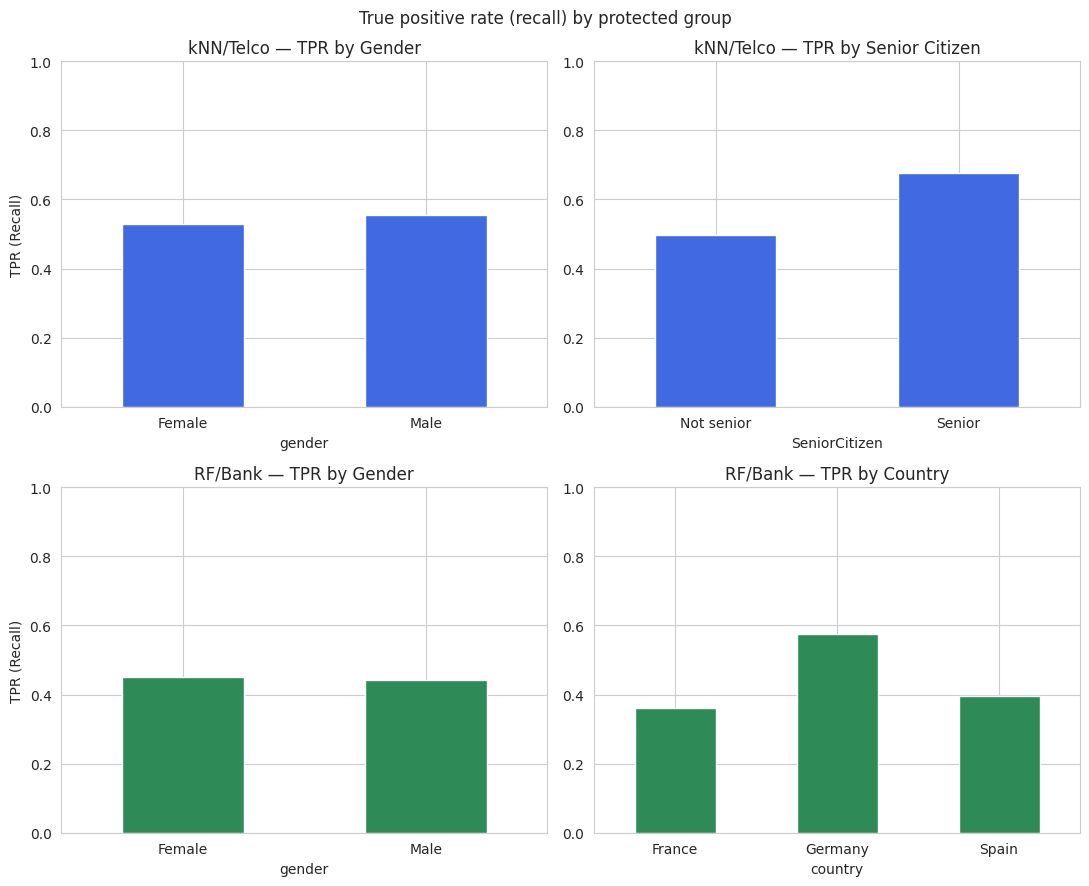

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

mf_gender_t.by_group['TPR'].plot(kind='bar', ax=axes[0, 0], color='royalblue', rot=0)
axes[0, 0].set_title('kNN/Telco — TPR by Gender'); axes[0, 0].set_ylim(0, 1); axes[0, 0].set_ylabel('TPR (Recall)')

mf_senior_t.by_group['TPR'].plot(kind='bar', ax=axes[0, 1], color='royalblue', rot=0)
axes[0, 1].set_title('kNN/Telco — TPR by Senior Citizen'); axes[0, 1].set_ylim(0, 1)

mf_gender_b.by_group['TPR'].plot(kind='bar', ax=axes[1, 0], color='seagreen', rot=0)
axes[1, 0].set_title('RF/Bank — TPR by Gender'); axes[1, 0].set_ylim(0, 1); axes[1, 0].set_ylabel('TPR (Recall)')

mf_country_b.by_group['TPR'].plot(kind='bar', ax=axes[1, 1], color='seagreen', rot=0)
axes[1, 1].set_title('RF/Bank — TPR by Country'); axes[1, 1].set_ylim(0, 1)

fig.suptitle('True positive rate (recall) by protected group')
plt.tight_layout()
plt.savefig('fig4_tpr_by_group.png', dpi=150)
plt.show()


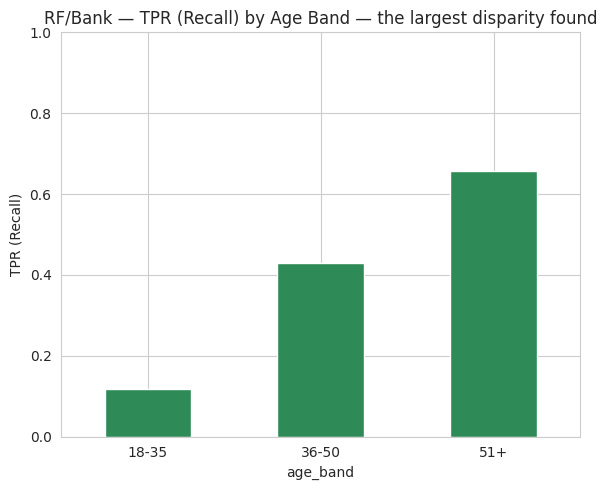

In [15]:
plt.figure(figsize=(6, 5))
mf_age_b.by_group['TPR'].plot(kind='bar', color='seagreen', rot=0)
plt.title('RF/Bank — TPR (Recall) by Age Band — the largest disparity found')
plt.ylabel('TPR (Recall)')
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('fig5_tpr_by_age.png', dpi=150)
plt.show()
